# Chapitre 2 - Cours 4 : L'échantillonnage et la nature probabiliste des modèles

Pour l'autrice, l'échantillonnage est l'un des concepts les plus sous-estimés de l'IA :
il explique des comportements déroutants (incohérences, hallucinations) et, bien
choisi, améliore nettement un modèle pour un effort minime. Ce notebook couvre la
section *Sampling* du livre :

- *Sampling Fundamentals* : logits, softmax, décodage glouton ;
- *Sampling Strategies* : température, logprobs, top-k, top-p, conditions d'arrêt ;
- *Test Time Compute* : best-of-N, sélection par logprob, vote majoritaire
  (*self-consistency*), mesurés sur un vrai modèle ;
- *Structured Outputs* : prompt, post-traitement, et **décodage contraint** par masque de
  logits (JSON et liste d'étiquettes) ;
- *The Probabilistic Nature of AI* : incohérence et hallucination, mesurées.

**Plan.** 1. Des logits aux probabilités ; 2. La température ; 3. Les logprobs ;
4. Top-k, top-p et min-p ; 5. Conditions d'arrêt ; 6. Test time compute ; 7. Sorties
structurées ; 8. Nature probabiliste : l'incohérence ; 9. Les hallucinations ; Synthèse.

In [1]:
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch02_modeles as m
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.max_colwidth", 110)
BASE_QWEN = "Qwen/Qwen2.5-0.5B"
tok, model = llm.load(llm.SMALL)


def short(txt, n=160):
    txt = " ".join(str(txt).split())
    return txt if len(txt) <= n else txt[:n] + " [...]"


def chat_logits(prompt, model_id=llm.SMALL, prefix=""):
    """Logits complets du prochain token après un prompt mis en forme (et un début de réponse optionnel)."""
    t, mdl = llm.load(model_id)
    text = t.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                 add_generation_prompt=True) + prefix
    ids = t(text, return_tensors="pt", add_special_tokens=False)["input_ids"].to(mdl.device)
    with torch.no_grad():
        return mdl(ids).logits[0, -1].float().cpu().numpy()

## 1. Des logits aux probabilités (section *Sampling Fundamentals*)

Un classifieur de spam calcule deux probabilités (spam, non-spam) puis décide. Un modèle
de langue fait de même sur **tout son vocabulaire** : pour chaque contexte, il produit un
vecteur de **logits** $x \in \mathbb R^{V}$, un score par token (151 936 pour Qwen2.5).
Les logits ne sont pas des probabilités : ils peuvent être négatifs et ne somment pas à
1. La **softmax** les transforme :
$$p_i = \operatorname{softmax}(x)_i = \frac{e^{x_i}}{\sum_{j=1}^V e^{x_j}} .$$
Regardons la vraie distribution du modèle de base Qwen2.5-0.5B après l'exemple du
livre, « My favorite color is ».

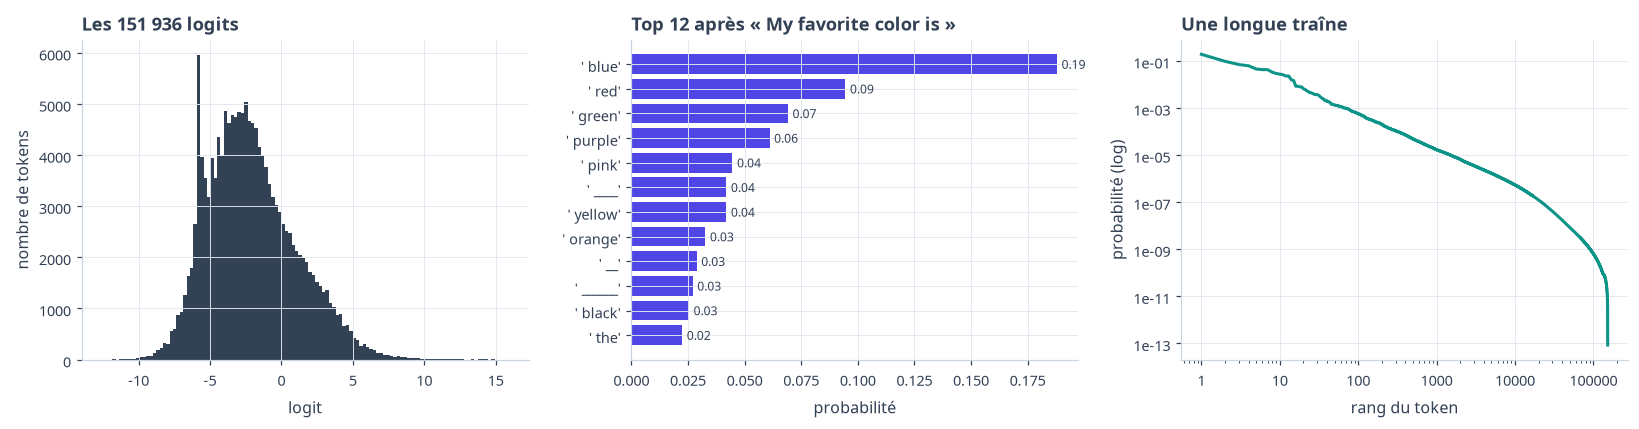

somme des probabilités : 1.000000 ; tokens nécessaires pour 90 % de la masse : 105


In [2]:
ctx = "My favorite color is"
z = llm.full_logits(ctx, BASE_QWEN)
p = llm.softmax(z)
tok_b, _ = llm.load(BASE_QWEN)
order = np.argsort(-p)
top = order[:12]
labels_top = [repr(tok_b.decode([i])) for i in top]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.hist(z, bins=120, color=SLATE)
ax.set_xlabel("logit"); ax.set_ylabel("nombre de tokens"); ax.set_title(f"Les {len(z):,} logits".replace(",", " "))
ax = axes[1]
ax.barh(labels_top[::-1], p[top][::-1], color=INDIGO)
annotate_bars(ax, "{:.2f}", fontsize=8)
ax.set_xlabel("probabilité"); ax.set_title(f"Top 12 après « {ctx} »")
ax = axes[2]
ax.loglog(np.arange(1, len(p) + 1), p[order], color=TEAL)
ax.set_xlabel("rang du token"); ax.set_ylabel("probabilité (log)"); ax.set_title("Une longue traîne")
m.plain_log_axis(ax); m.plain_log_axis(ax, "y", lambda v: f"{v:.0e}")
plt.tight_layout(); plt.show()
print(f"somme des probabilités : {p.sum():.6f} ; tokens nécessaires pour 90 % de la masse : "
      f"{np.searchsorted(np.cumsum(p[order]), 0.9) + 1}")

Le **décodage glouton** (*greedy*) prend toujours le token le plus probable : parfait pour
un classifieur, mais pour un modèle de langue il produit des textes ternes, toujours les
mêmes mots communs. On préfère **échantillonner** selon la distribution : si « red » a
30 % de chances, il sera choisi 30 % du temps. Dix tirages indépendants :

In [3]:
r = np.random.default_rng(1)
draws = [tok_b.decode([m.sample_token(z, r)]) for _ in range(10)]
print("glouton     :", repr(tok_b.decode([int(np.argmax(z))])))
print("échantillons:", draws)

glouton     : ' blue'
échantillons: [' blue', ' Zh', ' __', ' ______', ' known', ' blue', ' purple', ' green', ' blue', ' a']


> **À retenir.** Le modèle ne produit pas un mot mais une **distribution** sur tout le
> vocabulaire. Le glouton prend le maximum ; l'échantillonnage tire au sort selon les
> probabilités, et c'est là que s'introduit l'aléa.

## 2. La température (section *Temperature*)

Pour rendre les réponses plus ou moins « créatives », on divise les logits par une
**température** $T > 0$ avant la softmax :
$$p_i(T) = \frac{e^{x_i / T}}{\sum_j e^{x_j / T}} .$$
Le rapport de deux probabilités vaut $p_i/p_j = e^{(x_i - x_j)/T}$ : une basse température
amplifie les écarts (le favori rafle tout), une haute température les écrase (vers
l'uniforme). L'ordre des tokens, lui, ne change jamais. Exemple du livre : deux tokens A et
B de logits $[1, 2]$.

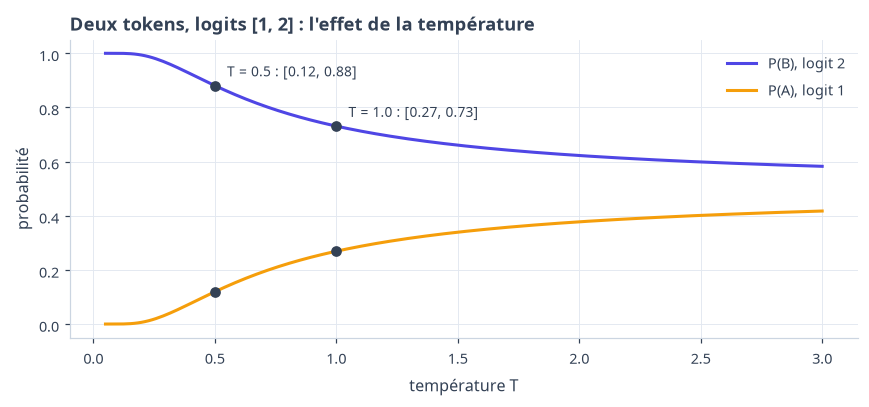

In [4]:
Ts = np.linspace(0.05, 3, 200)
pAB = np.array([llm.softmax(np.array([1.0, 2.0]), t) for t in Ts])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(Ts, pAB[:, 1], color=INDIGO, label="P(B), logit 2")
ax.plot(Ts, pAB[:, 0], color=AMBER, label="P(A), logit 1")
for t in [0.5, 1.0]:
    pb = llm.softmax(np.array([1.0, 2.0]), t)
    ax.plot([t, t], [pb[0], pb[1]], "o", color=SLATE)
    ax.annotate(f"T = {t} : [{pb[0]:.2f}, {pb[1]:.2f}]", (t, pb[1]), xytext=(8, 6), textcoords="offset points",
                fontsize=9)
ax.set_xlabel("température T"); ax.set_ylabel("probabilité"); ax.legend()
ax.set_title("Deux tokens, logits [1, 2] : l'effet de la température")
plt.tight_layout(); plt.show()

Sur la vraie distribution, et en mesurant l'**entropie** $H = -\sum_i p_i \log p_i$
(le « nombre effectif » de choix vaut $e^H$) :

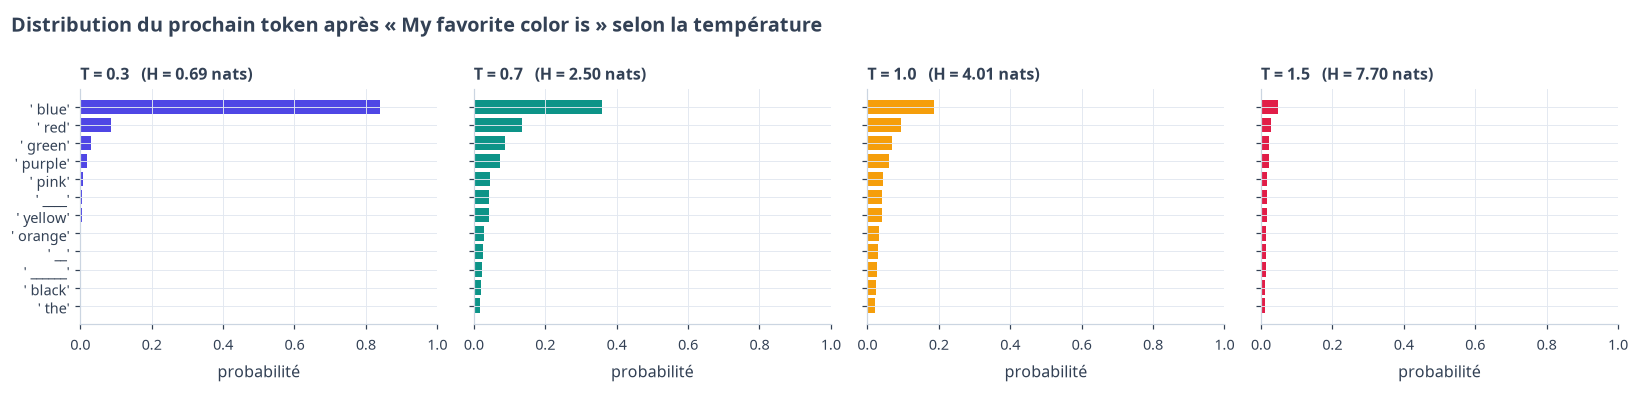

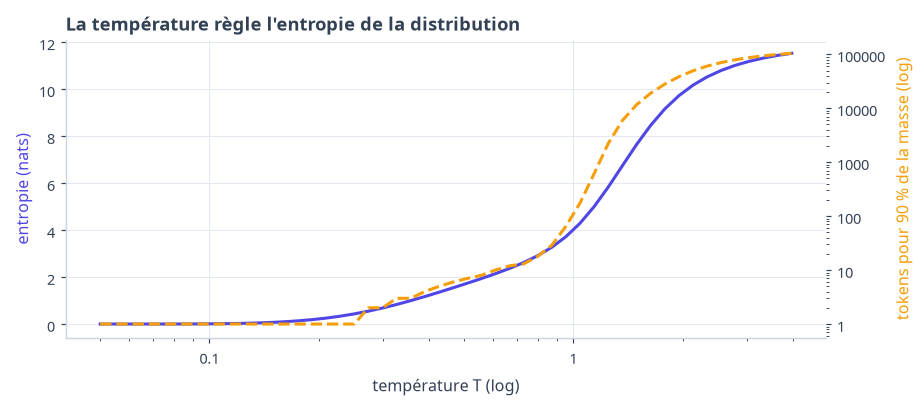

In [5]:
temps = [0.3, 0.7, 1.0, 1.5]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, t, c in zip(axes, temps, [INDIGO, TEAL, AMBER, ROSE]):
    pt = llm.softmax(z, t)
    ax.barh(labels_top[::-1], pt[top][::-1], color=c)
    ax.set_title(f"T = {t}   (H = {m.entropy(pt):.2f} nats)", fontsize=10.5)
    ax.set_xlim(0, 1); ax.set_xlabel("probabilité")
finish(fig, f"Distribution du prochain token après « {ctx} » selon la température")
plt.show()

Tgrid = np.logspace(-1.3, 0.6, 50)
H = [m.entropy(llm.softmax(z, t)) for t in Tgrid]
n90 = [np.searchsorted(np.cumsum(np.sort(llm.softmax(z, t))[::-1]), 0.9) + 1 for t in Tgrid]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.semilogx(Tgrid, H, color=INDIGO, label="entropie (nats)")
ax.set_xlabel("température T (log)"); ax.set_ylabel("entropie (nats)", color=INDIGO)
ax2 = ax.twinx(); ax2.grid(False)
ax2.semilogx(Tgrid, n90, color=AMBER, ls="--", label="tokens pour 90 % de la masse")
ax2.set_yscale("log"); ax2.set_ylabel("tokens pour 90 % de la masse (log)", color=AMBER)
m.plain_log_axis(ax2, "y"); m.plain_log_axis(ax)
ax.set_title("La température règle l'entropie de la distribution")
plt.tight_layout(); plt.show()

L'entropie croît **toujours** avec la température : on montre (exercice 2.8) que
$\frac{dH}{dT} = \frac{\operatorname{Var}_{p(T)}(x)}{T^3} \ge 0$. À $T = 0$, on ne peut pas
diviser par zéro : par convention, on prend l'argmax (décodage glouton). Les API limitent
souvent $T$ à $[0, 2]$ ; 0,7 est un réglage courant pour les usages créatifs. Effet sur des
générations complètes (notre propre boucle de génération `m.generate_custom`, graine fixée) :

In [6]:
prompt_creatif = "Écris la première phrase d'un roman de science-fiction."
rows = []
for t in [0.0, 0.7, 1.2, 2.0]:
    txt, lps = m.generate_custom(prompt_creatif, max_new_tokens=40, temperature=t, seed=3)
    rows.append({"T": t, "génération": short(txt, 170), "logprob moyenne": round(float(lps.mean()), 2)})
pd.DataFrame(rows)

,T,génération,logprob moyenne
0,0.0,"""Le temps est perdu, mais la vie continue.""",-1.26
1,0.7,"""Quand la mer se transforme en ressemblance, les êtres humains sont effaçés.""",-1.72
2,1.2,"""Le retour des anges est un épisode magique et espagnolic de cyberspace""",-2.63
3,2.0,Intella Nay PayPal met tous ces seems rejuvenated spectrum antementionné piston اللجborn jejecure falling....,-11.84


À $T = 0$ la phrase est la plus « probable » ; vers $T = 1$ elle varie tout en restant
cohérente ; à $T = 2$, les tokens rares envahissent la génération, qui devient incohérente
(la logprob moyenne sous le modèle s'effondre).

> **À retenir.** La température divise les logits : $T < 1$ concentre la distribution,
> $T > 1$ l'aplatit. Elle règle le compromis entre cohérence (basse) et diversité
> (haute) ; $T = 0$ signifie décodage glouton.

## 3. Les logprobs

Les API renvoient souvent des **logprobs**, des probabilités en échelle logarithmique.
Raison : avec 100 000 tokens, beaucoup de probabilités sont minuscules, et leur produit
sur une séquence **sous-dépasse** (*underflow*) la précision machine. Démonstration avec
les probabilités réelles des tokens d'un texte d'environ 200 tokens :

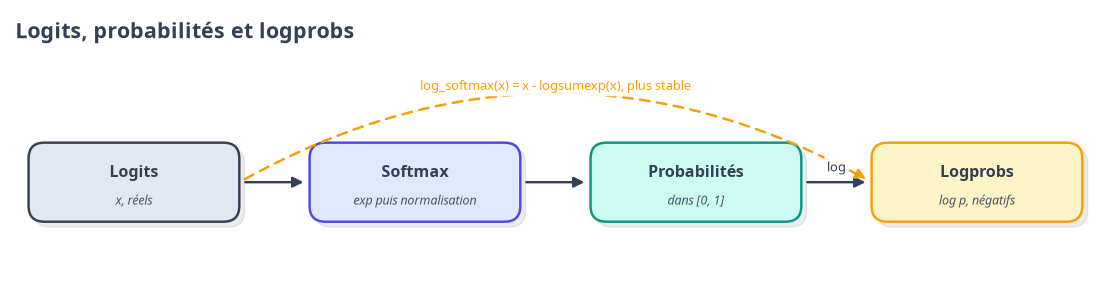

In [7]:
d = Diagram(12.5, 2.4, title="Logits, probabilités et logprobs")
d.flow([("lg", "Logits", "x, réels"), ("sm", "Softmax", "exp puis normalisation"), ("pr", "Probabilités", "dans [0, 1]"),
        ("lp", "Logprobs", "log p, négatifs")], y=1.0, x0=1.4, dx=3.2, w=2.4,
       labels=["", "", "log"], colors=[SLATE, INDIGO, TEAL, AMBER])
d.arrow("lg", "lp", "log_softmax(x) = x - logsumexp(x), plus stable", rad=-0.28, color=AMBER, style="dashed",
        label_offset=(0, 0.1))
d.show()

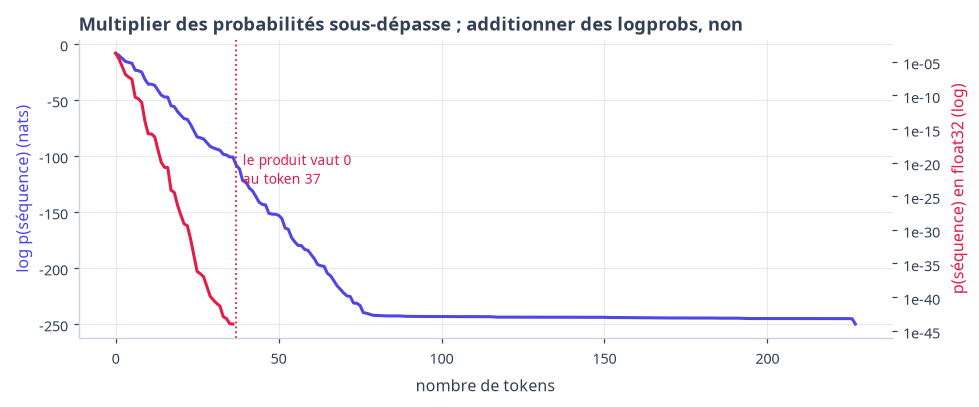

228 tokens : log p(séquence) = -250.4 nats, soit p = 10^-109


In [8]:
long_text = (" ".join(m.PARALLEL_CORPUS["en"]) + " The committee will publish its final report next week, "
             "after several months of public consultation with residents, local businesses and schools. ") * 3
toks_lt, lp_lt = llm.token_logprobs(long_text, BASE_QWEN)
probs32 = np.exp(lp_lt).astype(np.float32)
prod32 = np.cumprod(probs32)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.cumsum(lp_lt), color=INDIGO, label="somme des logprobs (stable)")
ax.set_xlabel("nombre de tokens"); ax.set_ylabel("log p(séquence) (nats)", color=INDIGO)
ax2 = ax.twinx(); ax2.grid(False)
ax2.semilogy(np.where(prod32 > 0, prod32, np.nan), color=ROSE, label="produit des probabilités (float32)")
ax2.set_ylabel("p(séquence) en float32 (log)", color=ROSE); m.plain_log_axis(ax2, "y", lambda v: f"{v:.0e}")
first0 = int(np.argmax(prod32 == 0)) if (prod32 == 0).any() else None
if first0:
    ax.axvline(first0, color=ROSE, ls=":", lw=1.2)
    ax.text(first0 + 2, np.cumsum(lp_lt).min() * 0.5, f"le produit vaut 0\nau token {first0}", color=ROSE, fontsize=9)
ax.set_title("Multiplier des probabilités sous-dépasse ; additionner des logprobs, non")
plt.tight_layout(); plt.show()
print(f"{len(lp_lt)} tokens : log p(séquence) = {lp_lt.sum():.1f} nats, soit p = 10^{lp_lt.sum() / np.log(10):.0f}")

(La courbe bleue s'aplatit après la première occurrence du paragraphe : celui-ci étant
répété trois fois, le modèle le recopie presque sans erreur, grâce aux têtes d'induction
du cours 1.) La probabilité réelle de ce texte, de l'ordre de $10^{-100}$ ou moins, n'est pas
représentable en float32 (plus petit nombre normal : $\approx 10^{-38}$) : le produit
devient exactement 0 après quelques dizaines de tokens. La somme des logprobs, elle, ne
pose aucun problème. Les logprobs servent partout dans le livre : classification,
évaluation (chapitre 3), sélection de sorties (section 6). Hélas, beaucoup d'API les
exposent peu (20 meilleurs tokens chez OpenAI au moment de l'écriture, aucun chez
Anthropic), en partie pour compliquer la copie des modèles.

> **À retenir.** On manipule les probabilités de séquences en **logprobs** : la
> log-probabilité d'une séquence est la somme des logprobs de ses tokens.